# 03. Stereo visual-inertial odometry without ground truth

Notebook 02 corrected the IMU with position fixes taken from the ground truth, which is an upper bound and not a real navigation system. This notebook replaces those fixes with stereo visual odometry (VO) computed from the DAVIS grayscale frames, so the estimate uses only the IMU and the two cameras on the hexacopter.

The two DAVIS cameras sit 10 cm apart. A corner seen in both images appears shifted sideways by a disparity $d$, and its depth is $Z = f b / d$, where $f$ is the focal length in pixels and $b$ is the baseline. Every tracked corner therefore has a depth in metres. Tracking those 3D points into the next left frame and solving Perspective-n-Point (PnP), the problem of finding the camera pose from known 3D points and their pixel positions, gives the motion between frames. Chaining the motions gives the trajectory, and the EKF from notebook 02 fuses it with the IMU.

The ground truth is still loaded, but only to score the result and to draw it in the figures. It never enters the VO or the filter.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))
from imu_tracking import data, evaluation, integration, plots

# Folder holding the MVSEC bags. Change this to wherever you downloaded them.
DATA_DIR = Path.home() / "Developer/Projects/event-vision-toolkit/data/raw/mvsec"
SEQUENCE_NAME = "indoor_flying4"
CALIBRATION_PATH = Path("../calibration/camchain_imucam_indoor_flying.yaml")
CACHE_PATH = Path(f"../data/{SEQUENCE_NAME}.npz")
FIGURE_DIR = Path("../figures")

# The hexacopter rests on the floor for about 3.5 s before the propellers spin up
STATIC_DURATION = 3.0

FIGURE_DIR.mkdir(exist_ok=True)
plots.use_paper_style()

from imu_tracking import ekf, stereo_vo

FRAME_CACHE_PATH = Path(f"../data/{SEQUENCE_NAME}_frames.npz")

In [2]:
sequence = data.load_sequence(
    DATA_DIR / f"{SEQUENCE_NAME}_data.bag",
    DATA_DIR / f"{SEQUENCE_NAME}_gt.bag",
    CACHE_PATH,
)
camera_from_imu_rotation, imu_origin_in_camera = data.load_imu_to_camera_extrinsics(CALIBRATION_PATH)

imu_time = sequence["imu_time"] - sequence["imu_time"][0]
accel = sequence["accel"]
gyro = sequence["gyro"]

imu_rate = 1 / np.median(np.diff(imu_time))
ground_truth_rate = 1 / np.median(np.diff(sequence["ground_truth_time"]))
print(f"IMU samples:          {len(imu_time)} at {imu_rate:.0f} Hz over {imu_time[-1]:.1f} s")
print(f"Ground-truth poses:   {len(sequence['ground_truth_time'])} at {ground_truth_rate:.0f} Hz")

IMU samples:          19862 at 1001 Hz over 19.8 s
Ground-truth poses:   1697 at 91 Hz


The next cell sets up the world frame from gravity, exactly as before. The ground-truth time offset and poses it computes are used only for evaluation.

In [3]:
static_result = data.estimate_static_biases(sequence, STATIC_DURATION)
gyro_bias = static_result["gyro_bias"]
accel_bias = static_result["accel_bias"]

world_from_first_camera = data.build_world_frame(static_result["up_direction_in_imu"], camera_from_imu_rotation)
camera_tilt = np.degrees(np.arccos(np.dot(world_from_first_camera[2], [0.0, -1.0, 0.0])))

time_offset = data.estimate_ground_truth_time_offset(sequence, camera_from_imu_rotation)
ground_truth_time, ground_truth_positions, ground_truth_rotations = data.ground_truth_imu_poses(
    sequence, world_from_first_camera, camera_from_imu_rotation, imu_origin_in_camera, time_offset
)
ground_truth_time = ground_truth_time - sequence["imu_time"][0]

# MVSEC ground truth starts at the identity, so the first IMU pose follows from the frame choice alone
initial_rotation = world_from_first_camera @ camera_from_imu_rotation
initial_position = ground_truth_positions[0]
imu_from_body_rotation = initial_rotation.T

print(f"|accel| at rest:      {static_result['mean_accel_magnitude']:.3f} m/s^2 (gravity is 9.81)")
print(f"accel std at rest:    {np.round(static_result['accel_std_at_rest'], 3)} m/s^2")
print(f"gyro bias:            {np.round(gyro_bias, 4)} rad/s")
print(f"camera tilt at rest:  {camera_tilt:.1f} deg below horizontal")
print(f"ground-truth offset:  {time_offset * 1000:.1f} ms")

|accel| at rest:      8.771 m/s^2 (gravity is 9.81)
accel std at rest:    [0.106 0.233 0.146] m/s^2
gyro bias:            [-0.0151 -0.0224 -0.0099] rad/s
camera tilt at rest:  16.9 deg below horizontal
ground-truth offset:  -57.5 ms


## Stereo visual odometry

Both images are first undistorted and rectified with the MVSEC calibration, so that a point in the left image lies on the same row of the right image. The frames are dark, so local contrast is boosted (CLAHE) before corners are detected.

In [4]:
VO_SETTINGS = {
    "max_corners": 400,
    "corner_quality": 0.005,
    "min_corner_distance": 7,
    "max_row_difference": 1.0,       # px, rectified matches must stay on the same row
    "min_disparity": 1.0,            # px, about 20 m depth; farther points carry no depth information
    "min_points": 8,
    "pnp_reprojection_error": 1.5,   # px
    "pnp_iterations": 200,
    "optical_flow": {
        "winSize": (21, 21),
        "maxLevel": 3,
        "criteria": (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01),
    },
}

stereo_frames = stereo_vo.load_stereo_frames(DATA_DIR / f"{SEQUENCE_NAME}_data.bag", FRAME_CACHE_PATH)
rectification = stereo_vo.load_stereo_rectification(CALIBRATION_PATH)

left_time = stereo_frames["left_time"]
right_indices = stereo_vo.nearest_right_frames(left_time, stereo_frames["right_time"])
stereo_time_gap = np.abs(stereo_frames["right_time"][right_indices] - left_time)

print(f"Left frames:          {len(left_time)} at {1 / np.median(np.diff(left_time)):.1f} Hz")
print(f"Focal length:         {rectification['focal_length']:.1f} px, baseline {rectification['baseline'] * 100:.2f} cm")
print(f"Left-right time gap:  {np.median(stereo_time_gap) * 1000:.1f} ms")

Left frames:          623 at 31.4 Hz
Focal length:         199.7 px, baseline 9.99 cm
Left-right time gap:  14.0 ms


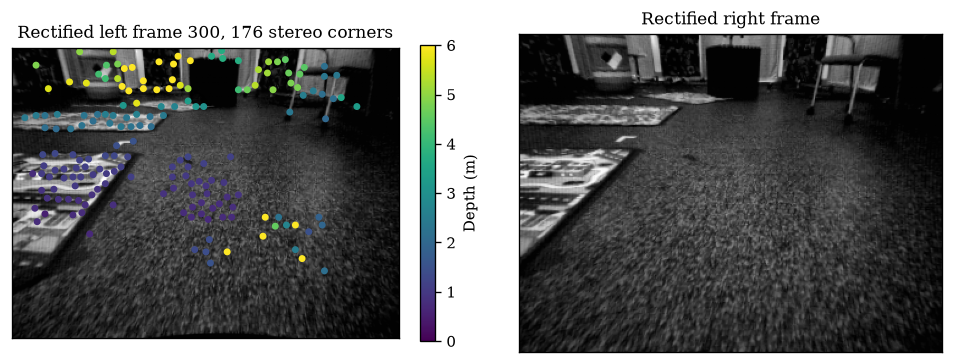

In [5]:
contrast_enhancer = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
EXAMPLE_FRAME = 300

example_left = stereo_vo.rectify_image(stereo_frames["left_images"][EXAMPLE_FRAME], rectification["cam0"], contrast_enhancer)
example_right = stereo_vo.rectify_image(
    stereo_frames["right_images"][right_indices[EXAMPLE_FRAME]], rectification["cam1"], contrast_enhancer
)
example_corners, example_points = stereo_vo.triangulate_stereo_corners(example_left, example_right, rectification, VO_SETTINGS)

figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(10, 3.6))
left_axis.imshow(example_left, cmap="gray")
depth_markers = left_axis.scatter(example_corners[:, 0], example_corners[:, 1], c=example_points[:, 2],
                                  cmap="viridis", s=10, vmin=0, vmax=6)
left_axis.set_title(f"Rectified left frame {EXAMPLE_FRAME}, {len(example_corners)} stereo corners")
right_axis.imshow(example_right, cmap="gray")
right_axis.set_title("Rectified right frame")
for axis in (left_axis, right_axis):
    axis.set_xticks([])
    axis.set_yticks([])
    axis.grid(False)
figure.colorbar(depth_markers, ax=left_axis, fraction=0.035, label="Depth (m)")
figure.savefig(FIGURE_DIR / "stereo_depth_example.png")
plt.show()

In [6]:
vo_camera_poses, vo_inlier_counts = stereo_vo.run_stereo_vo(stereo_frames, rectification, VO_SETTINGS)
vo_time = left_time - sequence["imu_time"][0]

vo_positions, vo_rotations = stereo_vo.camera_poses_to_world_imu(
    vo_camera_poses, world_from_first_camera, camera_from_imu_rotation, imu_origin_in_camera
)

tracked_frames = vo_inlier_counts[1:]
print(f"PnP inliers per frame: median {np.median(tracked_frames):.0f}, minimum {tracked_frames.min()}, "
      f"failed frames {(tracked_frames == 0).sum()}")

PnP inliers per frame: median 130, minimum 27, failed frames 0


## Fusing the VO with the IMU

Each VO position becomes a measurement for the same error-state EKF as in notebook 02, now at the 31 Hz frame rate. The VO positions are chained, so their errors are correlated over time and the filter cannot remove the slow drift. The IMU still contributes two things, a more accurate orientation and a pose estimate at 1 kHz instead of 31 Hz.

In [7]:
EKF_NOISE = {
    "accel_std": 3.0,
    "gyro_std": 0.001,
    "accel_bias_walk": 1e-3,
    "gyro_bias_walk": 1e-4,
    "fix_position_std": 0.05,        # m, frame-to-frame VO noise
    "initial_position_std": 0.01,
    "initial_velocity_std": 0.01,
    "initial_attitude_std": 0.01,
    "initial_accel_bias_std": 0.1,
    "initial_gyro_bias_std": 0.001,
}

vio_result = ekf.run_position_aided_ekf(
    imu_time, accel, gyro, vo_time[1:], vo_positions[1:],
    initial_rotation, vo_positions[0], accel_bias, gyro_bias,
    EKF_NOISE,
)

is_evaluated = ground_truth_time >= vo_time[0]
evaluation_time = ground_truth_time[is_evaluated]
evaluation_positions = ground_truth_positions[is_evaluated]
evaluation_rotations = ground_truth_rotations[is_evaluated]

vo_indices = evaluation.nearest_indices(vo_time, evaluation_time)
imu_indices = evaluation.nearest_indices(imu_time, evaluation_time)

vo_position_error = evaluation.position_errors(vo_positions[vo_indices], evaluation_positions)
vo_rotation_error = evaluation.rotation_errors_degrees(vo_rotations[vo_indices], evaluation_rotations)
vio_position_error = evaluation.position_errors(vio_result["positions"][imu_indices], evaluation_positions)
vio_rotation_error = evaluation.rotation_errors_degrees(vio_result["rotations"][imu_indices], evaluation_rotations)

path_length = np.sum(np.linalg.norm(np.diff(evaluation_positions, axis=0), axis=1))
print(f"Ground-truth path length {path_length:.2f} m\n")
evaluation.summarize("Stereo VO alone", vo_position_error, vo_rotation_error)
evaluation.summarize("EKF (IMU + stereo VO)", vio_position_error, vio_rotation_error)
print(f"\nFinal drift: VO {vo_position_error[-1]:.2f} m ({100 * vo_position_error[-1] / path_length:.1f}% of path), "
      f"EKF {vio_position_error[-1]:.2f} m ({100 * vio_position_error[-1] / path_length:.1f}% of path)")

Ground-truth path length 9.80 m

Stereo VO alone              position RMSE  0.304 m | max   0.71 m | rotation mean  0.92 deg | max  2.77 deg
EKF (IMU + stereo VO)        position RMSE  0.303 m | max   0.72 m | rotation mean  0.56 deg | max  2.54 deg

Final drift: VO 0.71 m (7.3% of path), EKF 0.72 m (7.3% of path)


## Figures

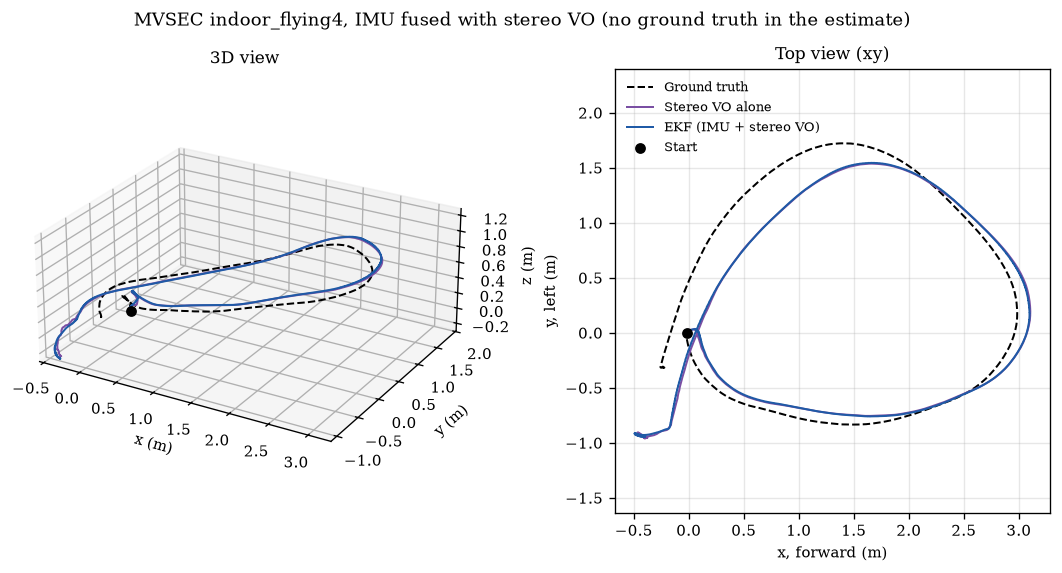

In [8]:
figure = plots.plot_trajectory(
    evaluation_positions,
    {"Stereo VO alone": vo_positions, "EKF (IMU + stereo VO)": vio_result["positions"]},
    title="MVSEC indoor_flying4, IMU fused with stereo VO (no ground truth in the estimate)",
)
figure.savefig(FIGURE_DIR / "trajectory_stereo_vio.png")
plt.show()

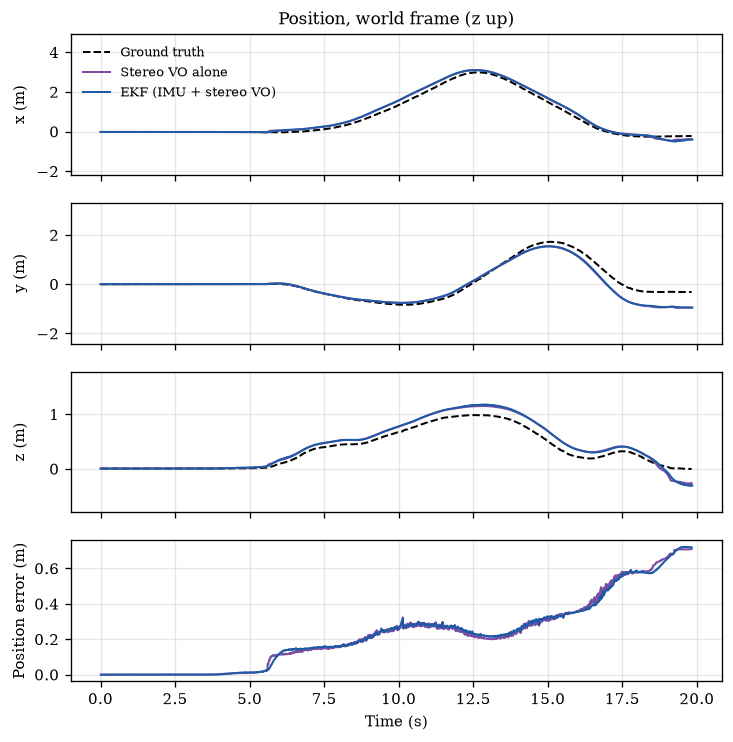

In [9]:
position_estimates = {
    "Stereo VO alone": (vo_time, vo_positions, vo_position_error),
    "EKF (IMU + stereo VO)": (imu_time, vio_result["positions"], vio_position_error),
}
figure = plots.plot_position_components(evaluation_time, evaluation_positions, position_estimates)
figure.savefig(FIGURE_DIR / "position_components_stereo_vio.png")
plt.show()

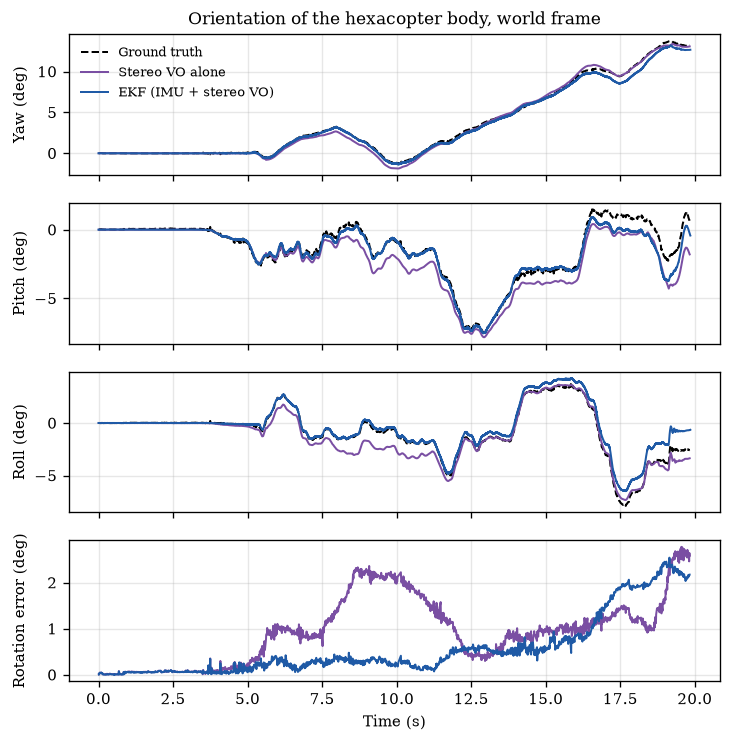

In [10]:
ground_truth_ypr = evaluation.body_euler_degrees(evaluation_rotations, imu_from_body_rotation)
vo_ypr = evaluation.body_euler_degrees(vo_rotations, imu_from_body_rotation)
vio_ypr = evaluation.body_euler_degrees(vio_result["rotations"], imu_from_body_rotation)
figure = plots.plot_orientation(
    evaluation_time, ground_truth_ypr,
    {
        "Stereo VO alone": (vo_time, vo_ypr, vo_rotation_error),
        "EKF (IMU + stereo VO)": (imu_time, vio_ypr, vio_rotation_error),
    },
)
figure.savefig(FIGURE_DIR / "orientation_stereo_vio.png")
plt.show()

In [11]:
ANIMATION_FPS = 15
ANIMATION_START = 4.0

frame_times = np.arange(ANIMATION_START, evaluation_time[-1], 1 / ANIMATION_FPS)
estimate_frames = evaluation.nearest_indices(imu_time, frame_times)
ground_truth_frames = evaluation.nearest_indices(ground_truth_time, frame_times)

imu_from_camera_rotation = camera_from_imu_rotation.T
estimate_camera_rotations = vio_result["rotations"][estimate_frames] @ imu_from_camera_rotation
ground_truth_camera_rotations = ground_truth_rotations[ground_truth_frames] @ imu_from_camera_rotation

plots.animate_flight(
    frame_times,
    vio_result["positions"][estimate_frames],
    estimate_camera_rotations,
    ground_truth_positions[ground_truth_frames],
    ground_truth_camera_rotations,
    FIGURE_DIR / "flight_stereo_vio.gif",
    estimate_name="EKF (IMU + stereo VO)",
    frames_per_second=ANIMATION_FPS,
)
print("saved", FIGURE_DIR / "flight_stereo_vio.gif")

saved ../figures/flight_stereo_vio.gif


## What this shows

Stereo VO alone reaches 0.30 m position RMSE over the 9.8 m flight and ends 0.71 m from the ground truth, a drift of 7.3% of the path length. It never lost tracking, and every frame kept at least 27 PnP inliers. Fusing it with the IMU leaves the position almost unchanged, because the filter receives chained VO positions whose errors carry over from one frame to the next. Orientation improves from 0.92 to 0.56 degrees mean error, since the gyro measures rotation more accurately than frame-to-frame PnP.

The error panel of `position_components_stereo_vio.png` shows two sources of drift. A step of about 0.1 m appears at take-off near t = 5.6 s, when the hexacopter leaves the floor within a few frames. After that the error grows slowly, mostly in y and z. Two likely causes are wrong stereo matches on the repetitive carpet texture (`stereo_depth_example.png` shows some floor corners placed near 6 m) and the 14 ms gap between the left and right exposures, which shifts the measured disparity whenever the camera moves sideways. Keyframe-based tracking and a tightly coupled filter that uses the feature tracks directly are the usual next steps.